# PointPillars — Evaluation & Visualization

Loads a checkpoint trained by the training notebook, runs it over the KITTI val split, reports BEV and 3D AP, and draws predictions on the camera images.

Needs `/content/kitti` (velodyne, label_2, calib) plus `image_2` for the pictures, and `/content/pointpillars.pth`.

Runtime -> Change runtime type -> GPU.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Cell 1 - Setup. image_2 is ~12 GB; skip this download if you only want numbers, not pictures.
!pip -q install shapely
%cd /content/kitti
!wget -nc https://s3.eu-central-1.amazonaws.com/avg-kitti/data_object_image_2.zip
!unzip -n -q data_object_image_2.zip 'training/*'
!rm -f data_object_image_2.zip
import os
print("images:", len(os.listdir("/content/kitti/training/image_2")))

/content/kitti
--2026-10-11 14:38:55--  https://s3.eu-central-1.amazonaws.com/avg-kitti/data_object_image_2.zip
Resolving s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)... 3.5.121.26, 3.5.136.48, 52.219.170.233, ...
Connecting to s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)|3.5.121.26|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12569945557 (12G) [application/zip]
Saving to: ‘data_object_image_2.zip’

data_object_image_2 100%[===================>]  11.71G  20.3MB/s    in 10m 15s 

2026-10-11 14:49:10 (19.5 MB/s) - ‘data_object_image_2.zip’ saved [12569945557/12569945557]

images: 7481


In [14]:
# Cell 2 - Model + data definitions (needed to load the checkpoint)
import os, math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F

CFG = dict(root="/content/kitti", pc_range=[0, -39.68, -3, 69.12, 39.68, 1],
           voxel_size=[0.16, 0.16, 4], max_pts=32, max_pillars=12000, cls_name="Car",
           anchor_size=[3.9, 1.6, 1.56], anchor_bottom=-1.78, dir_offset=0.78539)
CFG["nx"] = int(round((CFG["pc_range"][3] - CFG["pc_range"][0]) / CFG["voxel_size"][0]))
CFG["ny"] = int(round((CFG["pc_range"][4] - CFG["pc_range"][1]) / CFG["voxel_size"][1]))
CFG["fx"], CFG["fy"] = CFG["nx"] // 2, CFG["ny"] // 2
DEV = "cuda" if torch.cuda.is_available() else "cpu"

def read_calib(p):
    d = {}
    for line in open(p):
        if ":" not in line: continue
        k, v = line.split(":", 1)
        d[k] = np.array([float(x) for x in v.split()], np.float32)
    P2 = d["P2"].reshape(3, 4)
    R0 = np.eye(4, dtype=np.float32); R0[:3, :3] = d["R0_rect"].reshape(3, 3)
    V2C = np.eye(4, dtype=np.float32); V2C[:3, :4] = d["Tr_velo_to_cam"].reshape(3, 4)
    return P2, R0, V2C

def cam_to_lidar(pts, R0, V2C):
    p = np.hstack([pts, np.ones((len(pts), 1), np.float32)])
    return (np.linalg.inv(V2C) @ np.linalg.inv(R0) @ p.T).T[:, :3]

def fov_filter(pts, P2, R0, V2C, img=(375, 1242)):
    p = np.hstack([pts[:, :3], np.ones((len(pts), 1), np.float32)])
    cam = (R0 @ V2C @ p.T).T
    uv = (P2 @ cam.T).T
    uv = uv[:, :2] / np.clip(uv[:, 2:3], 1e-6, None)
    m = (cam[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < img[1]) & (uv[:, 1] >= 0) & (uv[:, 1] < img[0])
    return pts[m]

def read_label(p, cls, R0, V2C):
    loc, dim, ry = [], [], []
    for line in open(p):
        f = line.split()
        if f[0] != cls: continue
        dim.append([float(f[10]), float(f[9]), float(f[8])])          # l, w, h
        loc.append([float(f[11]), float(f[12]), float(f[13])])
        ry.append(float(f[14]))
    if not loc: return np.zeros((0, 7), np.float32)
    loc = cam_to_lidar(np.array(loc, np.float32), R0, V2C)
    dim = np.array(dim, np.float32); ry = np.array(ry, np.float32)
    loc[:, 2] += dim[:, 2] / 2
    return np.concatenate([loc, dim, (-(ry + np.pi / 2))[:, None]], 1).astype(np.float32)

def pillarize(points, cfg):
    pr, vs = cfg["pc_range"], cfg["voxel_size"]
    m = ((points[:, 0] >= pr[0]) & (points[:, 0] < pr[3]) & (points[:, 1] >= pr[1]) &
         (points[:, 1] < pr[4]) & (points[:, 2] >= pr[2]) & (points[:, 2] < pr[5]))
    points = points[m]
    N, P = cfg["max_pts"], cfg["max_pillars"]
    if len(points) == 0:
        return np.zeros((1, N, 4), np.float32), np.zeros((1, 2), np.int32), np.ones(1, np.int32)
    coords = np.floor((points[:, :2] - np.array(pr[:2], np.float32)) / np.array(vs[:2], np.float32))
    coords = np.clip(coords, 0, [cfg["nx"] - 1, cfg["ny"] - 1]).astype(np.int32)
    key = coords[:, 1] * cfg["nx"] + coords[:, 0]
    o = np.argsort(key, kind="stable")
    points, coords, key = points[o], coords[o], key[o]
    uk, start, cnt = np.unique(key, return_index=True, return_counts=True)
    npil = len(uk)
    idx_in = np.arange(len(points)) - np.repeat(start, cnt)
    pid = np.repeat(np.arange(npil), cnt)
    v = idx_in < N
    feat = np.zeros((npil, N, 4), np.float32)
    feat[pid[v], idx_in[v]] = points[v, :4]
    num = np.minimum(cnt, N).astype(np.int32)
    coo = coords[start]
    if npil > P:
        sel = np.random.choice(npil, P, replace=False)
        feat, coo, num = feat[sel], coo[sel], num[sel]
    return feat, coo, num

class KittiVal(torch.utils.data.Dataset):
    def __init__(self, cfg, split="val"):
        self.cfg = cfg; self.dir = cfg["root"] + "/training"
        ids = [l.strip() for l in open(f"{cfg['root']}/ImageSets/{split}.txt") if l.strip()]
        have = {f[:-4] for f in os.listdir(self.dir + "/velodyne")}
        self.ids = [i for i in ids if i in have]
    def __len__(self): return len(self.ids)
    def load(self, k):
        i = self.ids[k]
        pts = np.fromfile(f"{self.dir}/velodyne/{i}.bin", np.float32).reshape(-1, 4).copy()
        P2, R0, V2C = read_calib(f"{self.dir}/calib/{i}.txt")
        return fov_filter(pts, P2, R0, V2C), read_label(f"{self.dir}/label_2/{i}.txt",
                                                        self.cfg["cls_name"], R0, V2C), i, (P2, R0, V2C)
    def __getitem__(self, k):
        pts, gt, fid, _ = self.load(k)
        f, c, n = pillarize(pts, self.cfg)
        return dict(pillars=f, coords=c, num=n, gt=gt, fid=fid)

def collate(batch):
    coo = [np.pad(b["coords"], ((0, 0), (1, 0)), constant_values=i) for i, b in enumerate(batch)]
    return dict(pillars=torch.from_numpy(np.concatenate([b["pillars"] for b in batch])),
                coords=torch.from_numpy(np.concatenate(coo)).long(),
                num=torch.from_numpy(np.concatenate([b["num"] for b in batch])).long(),
                gt=[b["gt"] for b in batch], fid=[b["fid"] for b in batch], bs=len(batch))

def to_dev(b):
    for k in ("pillars", "coords", "num"): b[k] = b[k].to(DEV, non_blocking=True)
    return b

class PFN(nn.Module):
    def __init__(self, cfg, out=64):
        super().__init__(); self.cfg = cfg
        self.lin = nn.Linear(9, out, bias=False)
        self.bn = nn.BatchNorm1d(out, eps=1e-3, momentum=0.01)
    def forward(self, p, c, n):
        pr, vs = self.cfg["pc_range"], self.cfg["voxel_size"]
        N = p.shape[1]
        mask = (torch.arange(N, device=p.device)[None] < n[:, None]).unsqueeze(-1).to(p.dtype)
        mean = (p[..., :3] * mask).sum(1, keepdim=True) / n.clamp(min=1)[:, None, None]
        cx = (c[:, 1].to(p.dtype) + 0.5) * vs[0] + pr[0]
        cy = (c[:, 2].to(p.dtype) + 0.5) * vs[1] + pr[1]
        f = torch.cat([p, p[..., :3] - mean,
                       torch.stack([p[..., 0] - cx[:, None], p[..., 1] - cy[:, None]], -1)], -1) * mask
        f = F.relu(self.bn(self.lin(f).transpose(1, 2)).transpose(1, 2)) * mask
        return f.max(1)[0]

def scatter(feats, coords, bs, cfg):
    C = feats.shape[1]
    canvas = feats.new_zeros(bs, C, cfg["ny"] * cfg["nx"])
    idx = (coords[:, 2] * cfg["nx"] + coords[:, 1]).clamp_(0, cfg["ny"] * cfg["nx"] - 1)
    canvas[coords[:, 0], :, idx] = feats
    return canvas.view(bs, C, cfg["ny"], cfg["nx"])

def cbr(i, o, k=3, s=1, p=1):
    return nn.Sequential(nn.Conv2d(i, o, k, s, p, bias=False),
                         nn.BatchNorm2d(o, eps=1e-3, momentum=0.01), nn.ReLU(inplace=True))

class Backbone(nn.Module):
    def __init__(self, inc=64):
        super().__init__()
        bl = [(inc, 64, 4, 2), (64, 128, 6, 2), (128, 256, 6, 2)]
        up = [(64, 128, 1), (128, 128, 2), (256, 128, 4)]
        self.blocks = nn.ModuleList(nn.Sequential(cbr(i, o, 3, s, 1), *[cbr(o, o) for _ in range(n - 1)])
                                    for i, o, n, s in bl)
        self.ups = nn.ModuleList(nn.Sequential(nn.ConvTranspose2d(i, o, s, s, bias=False),
                                 nn.BatchNorm2d(o, eps=1e-3, momentum=0.01), nn.ReLU(inplace=True))
                                 for i, o, s in up)
    def forward(self, x):
        outs = []
        for b, u in zip(self.blocks, self.ups):
            x = b(x); outs.append(u(x))
        return torch.cat(outs, 1)

class Head(nn.Module):
    def __init__(self, inc=384, na=2, nc=1):
        super().__init__(); self.na, self.nc = na, nc
        self.cls = nn.Conv2d(inc, na * nc, 1); self.box = nn.Conv2d(inc, na * 7, 1)
        self.dir = nn.Conv2d(inc, na * 2, 1)
    def forward(self, x):
        B = x.shape[0]
        f = lambda t, d: t.permute(0, 2, 3, 1).reshape(B, -1, d)
        return f(self.cls(x), self.nc), f(self.box(x), 7), f(self.dir(x), 2)

class PointPillars(nn.Module):
    def __init__(self, cfg):
        super().__init__(); self.cfg = cfg
        self.pfn = PFN(cfg, 64); self.backbone = Backbone(64); self.head = Head(384)
    def forward(self, b):
        f = self.pfn(b["pillars"], b["coords"], b["num"])
        return self.head(self.backbone(scatter(f, b["coords"], b["bs"], self.cfg)))

def make_anchors(cfg):
    pr, vs = cfg["pc_range"], cfg["voxel_size"]
    x = pr[0] + (torch.arange(cfg["fx"]) + 0.5) * vs[0] * 2
    y = pr[1] + (torch.arange(cfg["fy"]) + 0.5) * vs[1] * 2
    dx, dy, dz = cfg["anchor_size"]; z = cfg["anchor_bottom"] + dz / 2
    yy, xx = torch.meshgrid(y, x, indexing="ij")
    out = [torch.stack([xx, yy, torch.full_like(xx, z), torch.full_like(xx, dx),
                        torch.full_like(xx, dy), torch.full_like(xx, dz),
                        torch.full_like(xx, r)], -1) for r in (0.0, np.pi / 2)]
    return torch.stack(out, 2).reshape(-1, 7)

def limit_period(v, offset=0.5, period=np.pi):
    return v - torch.floor(v / period + offset) * period

def decode(p, a):
    d = torch.sqrt(a[:, 3] ** 2 + a[:, 4] ** 2)
    return torch.stack([p[:, 0] * d + a[:, 0], p[:, 1] * d + a[:, 1], p[:, 2] * a[:, 5] + a[:, 2],
                        torch.exp(p[:, 3]) * a[:, 3], torch.exp(p[:, 4]) * a[:, 4],
                        torch.exp(p[:, 5]) * a[:, 5], p[:, 6] + a[:, 6]], -1)

print("defs loaded |", DEV)

defs loaded | cuda


In [15]:
# Cell 3 - Load checkpoint
CKPT = "/content/pointpillars.pth"
model = PointPillars(CFG).to(DEV)
sd = torch.load(CKPT, map_location=DEV)
model.load_state_dict(sd["model"] if "model" in sd else sd)
model.eval()
ANCHORS = make_anchors(CFG).to(DEV)
ds = KittiVal(CFG)
print(len(ds), "val frames | anchors", tuple(ANCHORS.shape))

39 val frames | anchors (107136, 7)


In [16]:
# Cell 4 - Post-processing: decode -> score filter -> rotated BEV NMS
from shapely.geometry import Polygon

def corners_bev(b):
    c, s = np.cos(b[6]), np.sin(b[6])
    p = np.array([[b[3] / 2, b[4] / 2], [b[3] / 2, -b[4] / 2],
                  [-b[3] / 2, -b[4] / 2], [-b[3] / 2, b[4] / 2]])
    return p @ np.array([[c, -s], [s, c]]).T + b[:2]

def iou_bev(a, b):
    pa, pb = Polygon(corners_bev(a)), Polygon(corners_bev(b))
    if not (pa.is_valid and pb.is_valid): return 0.0
    i = pa.intersection(pb).area
    return i / (pa.area + pb.area - i + 1e-9)

def iou_3d(a, b):
    pa, pb = Polygon(corners_bev(a)), Polygon(corners_bev(b))
    if not (pa.is_valid and pb.is_valid): return 0.0
    ov = pa.intersection(pb).area
    zl = max(a[2] - a[5] / 2, b[2] - b[5] / 2); zh = min(a[2] + a[5] / 2, b[2] + b[5] / 2)
    inter = ov * max(0.0, zh - zl)
    va, vb = a[3] * a[4] * a[5], b[3] * b[4] * b[5]
    return inter / (va + vb - inter + 1e-9)

def nms_bev(boxes, scores, thr=0.1, topk=100, pre=300):
    order = np.argsort(-scores)[:pre]; keep = []
    for i in order:
        if all(iou_bev(boxes[i], boxes[j]) <= thr for j in keep):
            keep.append(i)
            if len(keep) >= topk: break
    return keep

@torch.no_grad()
def predict(batch, score_thr=0.3, nms_thr=0.1):
    cls_p, box_p, dir_p = model(to_dev(batch))
    sc = torch.sigmoid(cls_p).squeeze(-1)
    out = []
    for b in range(batch["bs"]):
        m = sc[b] > score_thr
        if m.sum() == 0:
            out.append(np.zeros((0, 8), np.float32)); continue
        bx = decode(box_p[b][m].float(), ANCHORS[m])
        d = dir_p[b][m].argmax(-1).float()
        v = limit_period(bx[:, 6] - CFG["dir_offset"], 0.5, np.pi)
        bx[:, 6] = v + CFG["dir_offset"] + np.pi * d
        bx = bx.cpu().numpy(); s = sc[b][m].cpu().numpy()
        k = nms_bev(bx, s, nms_thr)
        out.append(np.concatenate([bx[k], s[k][:, None]], 1).astype(np.float32))
    return out

In [17]:
# Cell 5 - Run inference over the val split
from torch.utils.data import DataLoader
import time

dl = DataLoader(ds, 4, shuffle=False, num_workers=2, collate_fn=collate)
DETS, GTS, FIDS = [], [], []
t0 = time.time()
for i, b in enumerate(dl):
    GTS += b["gt"]; FIDS += b["fid"]
    DETS += predict(b)
    if i % 50 == 0: print(f"{i*4}/{len(ds)}  {time.time()-t0:.0f}s")
print("done:", len(DETS), "frames |", sum(len(d) for d in DETS), "detections")

0/39  4s
done: 39 frames | 187 detections


In [18]:
# Cell 6 - AP (40-point interpolation)
def ap_r40(dets, gts, thr, fn):
    npos = sum(len(g) for g in gts)
    flat = sorted(((d[7], i, d[:7]) for i, D in enumerate(dets) for d in D), key=lambda x: -x[0])
    seen = [np.zeros(len(g), bool) for g in gts]
    tp = np.zeros(len(flat)); fp = np.zeros(len(flat))
    for k, (_, i, b) in enumerate(flat):
        g = gts[i]
        if len(g) == 0: fp[k] = 1; continue
        ious = np.array([fn(b, x) for x in g]); j = int(ious.argmax())
        if ious[j] >= thr and not seen[i][j]: tp[k] = 1; seen[i][j] = True
        else: fp[k] = 1
    tp, fp = np.cumsum(tp), np.cumsum(fp)
    rec = tp / max(npos, 1); prec = tp / np.maximum(tp + fp, 1e-9)
    ap = sum((prec[rec >= r].max() if (rec >= r).any() else 0.0) for r in np.linspace(1/40, 1, 40)) / 40
    return ap * 100, rec, prec

for name, fn in (("BEV", iou_bev), ("3D ", iou_3d)):
    for thr in (0.7, 0.5):
        ap, _, _ = ap_r40(DETS, GTS, thr, fn)
        print(f"Car {name} AP@{thr}: {ap:5.2f}")

Car BEV AP@0.7: 74.02
Car BEV AP@0.5: 83.24
Car 3D  AP@0.7: 53.64
Car 3D  AP@0.5: 83.08


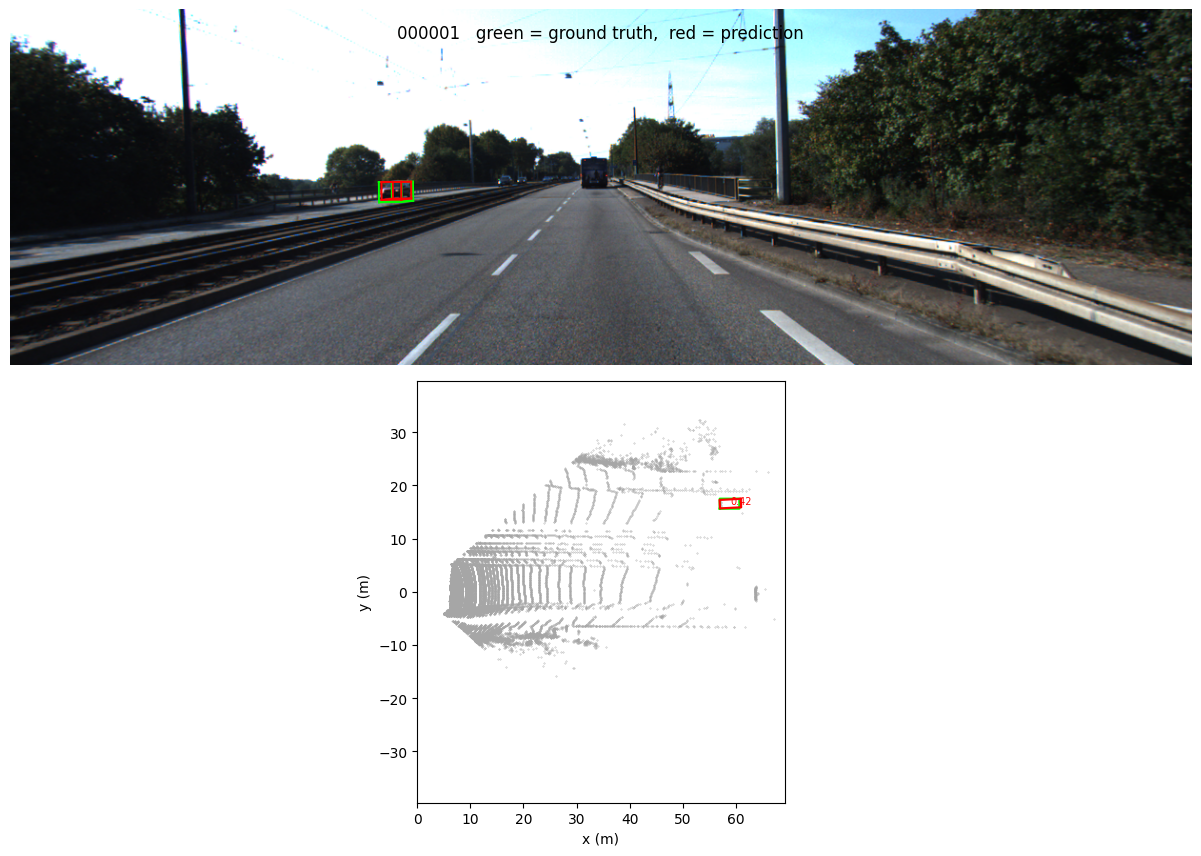

In [19]:
# Cell 7 - Draw 3D boxes on the camera image + BEV panel
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def box_corners_cam(b, R0, V2C):
    """lidar box (x,y,z,dx,dy,dz,yaw) -> 8 corners in rectified camera coords"""
    c, s = np.cos(b[6]), np.sin(b[6])
    dx, dy, dz = b[3], b[4], b[5]
    X = np.array([dx, dx, -dx, -dx, dx, dx, -dx, -dx]) / 2
    Y = np.array([dy, -dy, -dy, dy, dy, -dy, -dy, dy]) / 2
    Z = np.array([-dz, -dz, -dz, -dz, dz, dz, dz, dz]) / 2
    pts = np.stack([c * X - s * Y + b[0], s * X + c * Y + b[1], Z + b[2]], 1)
    return (R0 @ V2C @ np.hstack([pts, np.ones((8, 1))]).T).T[:, :3]

EDGES = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]

def project(c3d, P2):
    uv = (P2 @ np.hstack([c3d, np.ones((len(c3d), 1))]).T).T
    return uv[:, :2] / np.clip(uv[:, 2:3], 1e-6, None), uv[:, 2]

def show(idx, score_thr=0.4, save=None):
    pts, gt, fid, (P2, R0, V2C) = ds.load(idx)
    det = predict(collate([ds[idx]]), score_thr)[0]
    img = mpimg.imread(f"{CFG['root']}/training/image_2/{fid}.png")

    fig, ax = plt.subplots(2, 1, figsize=(14, 9),
                           gridspec_kw={"height_ratios": [img.shape[0] / img.shape[1] * 14, 5]})
    ax[0].imshow(img); ax[0].axis("off")
    for boxes, col in ((gt, "lime"), (det, "red")):
        for b in boxes:
            c3d = box_corners_cam(b, R0, V2C)
            if (c3d[:, 2] < 0.1).any(): continue
            uv, _ = project(c3d, P2)
            for i, j in EDGES:
                ax[0].plot(uv[[i, j], 0], uv[[i, j], 1], c=col, lw=1.4)
    ax[0].set_xlim(0, img.shape[1]); ax[0].set_ylim(img.shape[0], 0)

    pr = CFG["pc_range"]
    ax[1].scatter(pts[:, 0], pts[:, 1], s=0.08, c="0.65")
    for boxes, col in ((gt, "lime"), (det, "red")):
        for b in boxes:
            k = np.vstack([corners_bev(b), corners_bev(b)[:1]])
            ax[1].plot(k[:, 0], k[:, 1], c=col, lw=1.6)
    for b in det:
        ax[1].text(b[0], b[1], f"{b[7]:.2f}", color="red", fontsize=7)
    ax[1].set_xlim(pr[0], pr[3]); ax[1].set_ylim(pr[1], pr[4]); ax[1].set_aspect("equal")
    ax[1].set_xlabel("x (m)"); ax[1].set_ylabel("y (m)")
    fig.suptitle(f"{fid}   green = ground truth,  red = prediction", y=0.93)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=120, bbox_inches="tight")
    plt.show()

show(0)

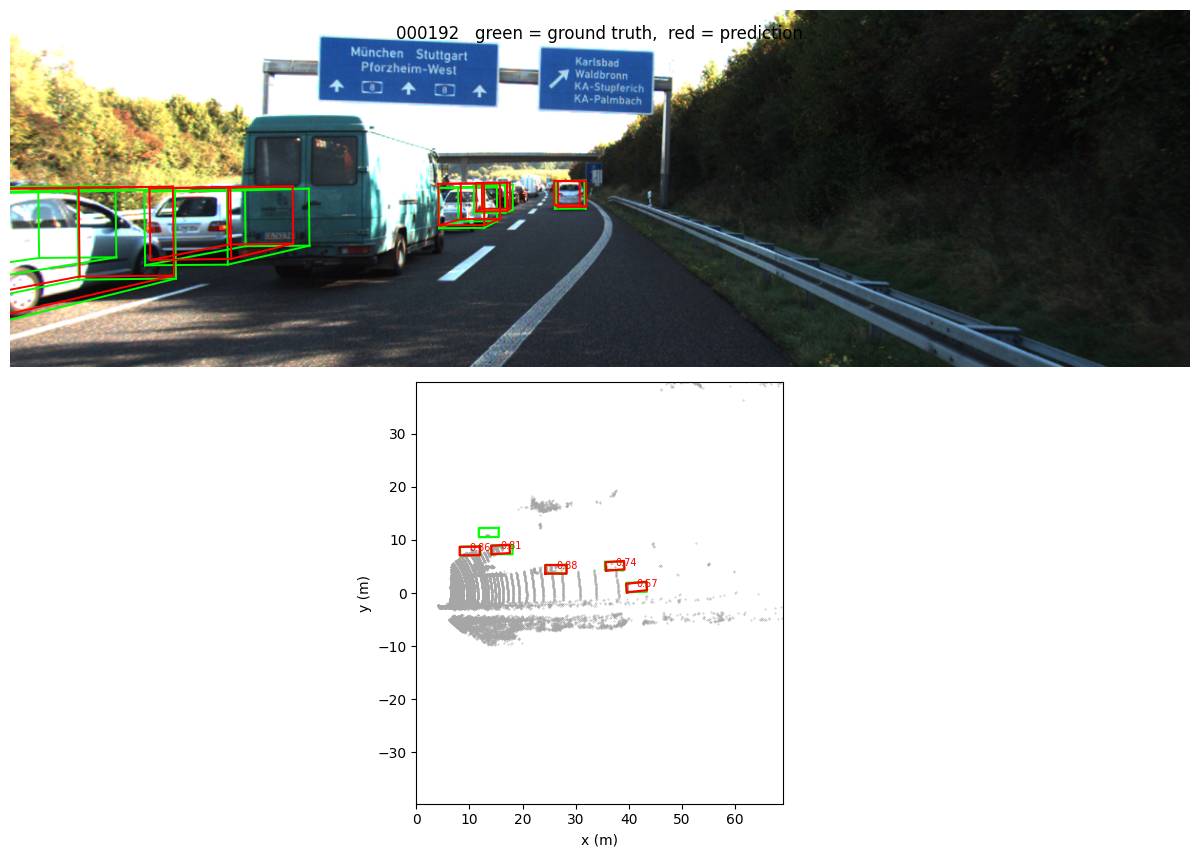

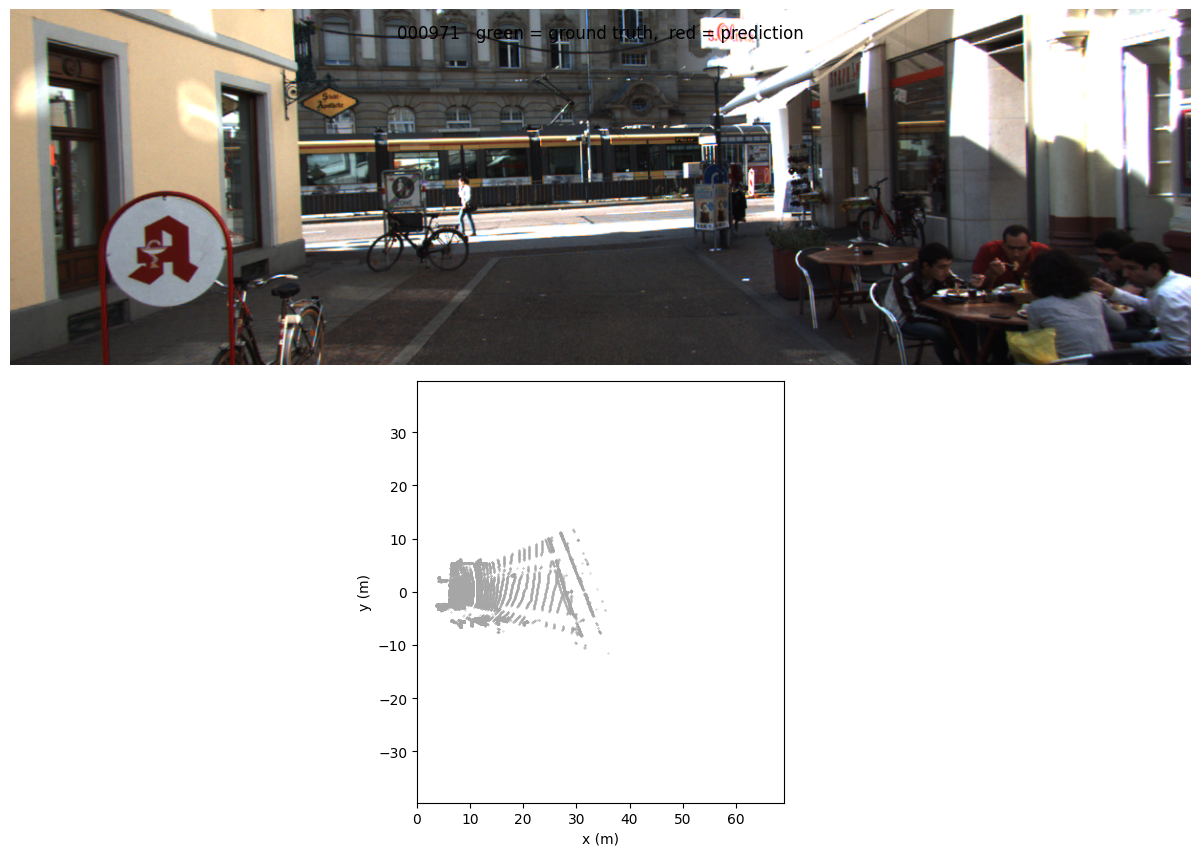

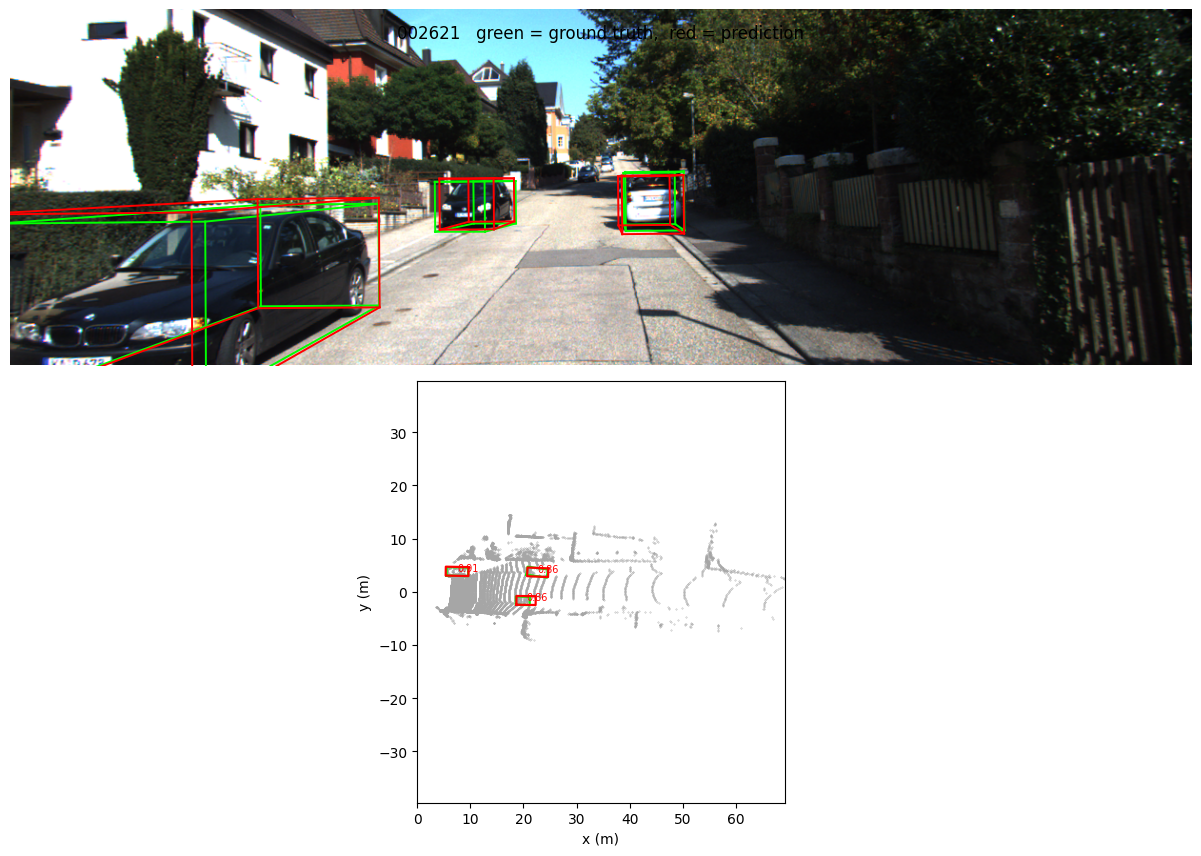

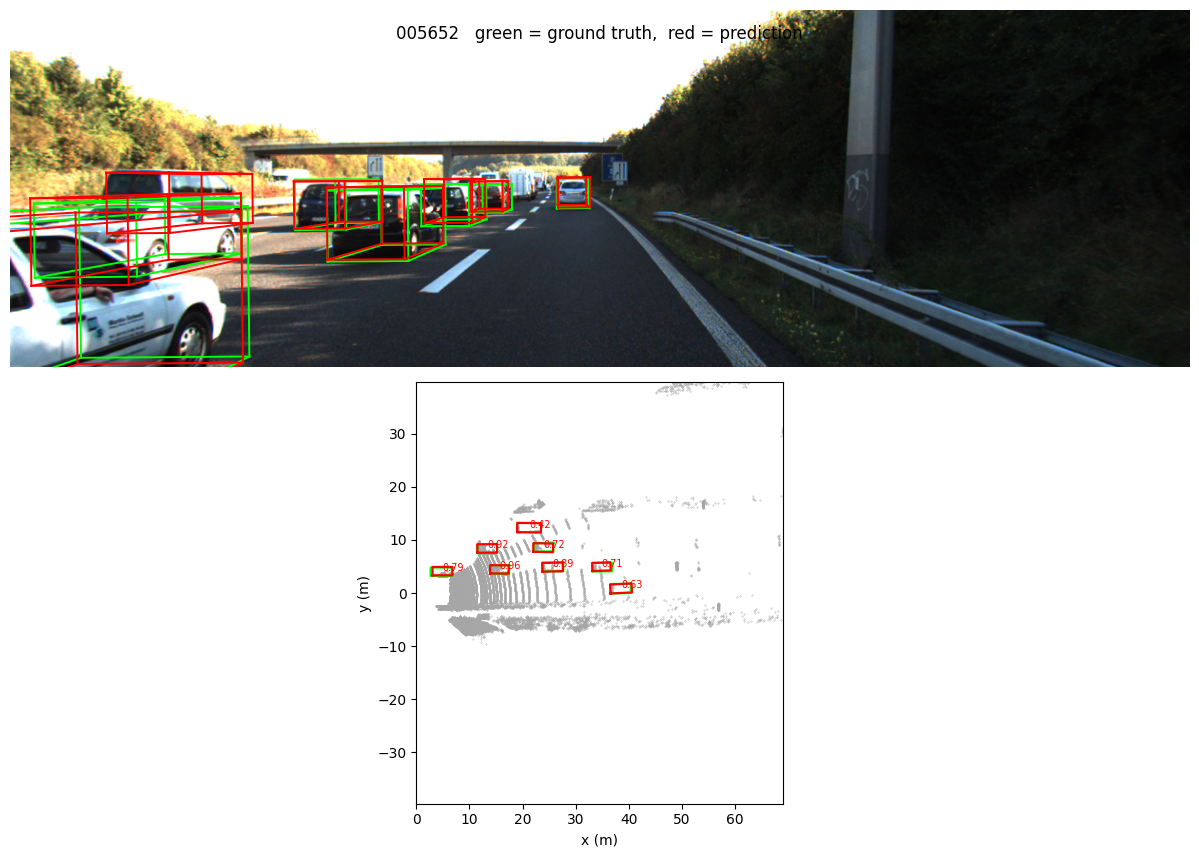

largest count mismatches: [('006052', 13, 6), ('004959', 12, 8), ('001108', 13, 10)]


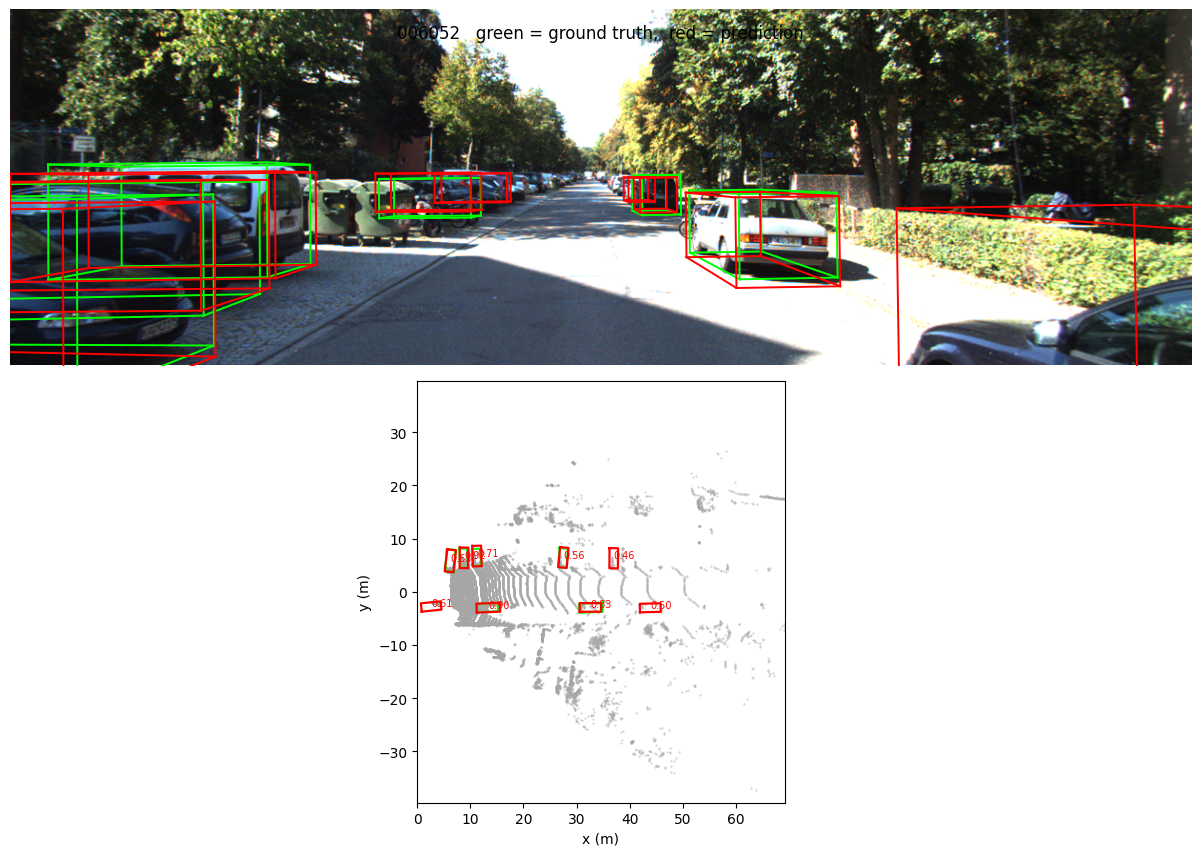

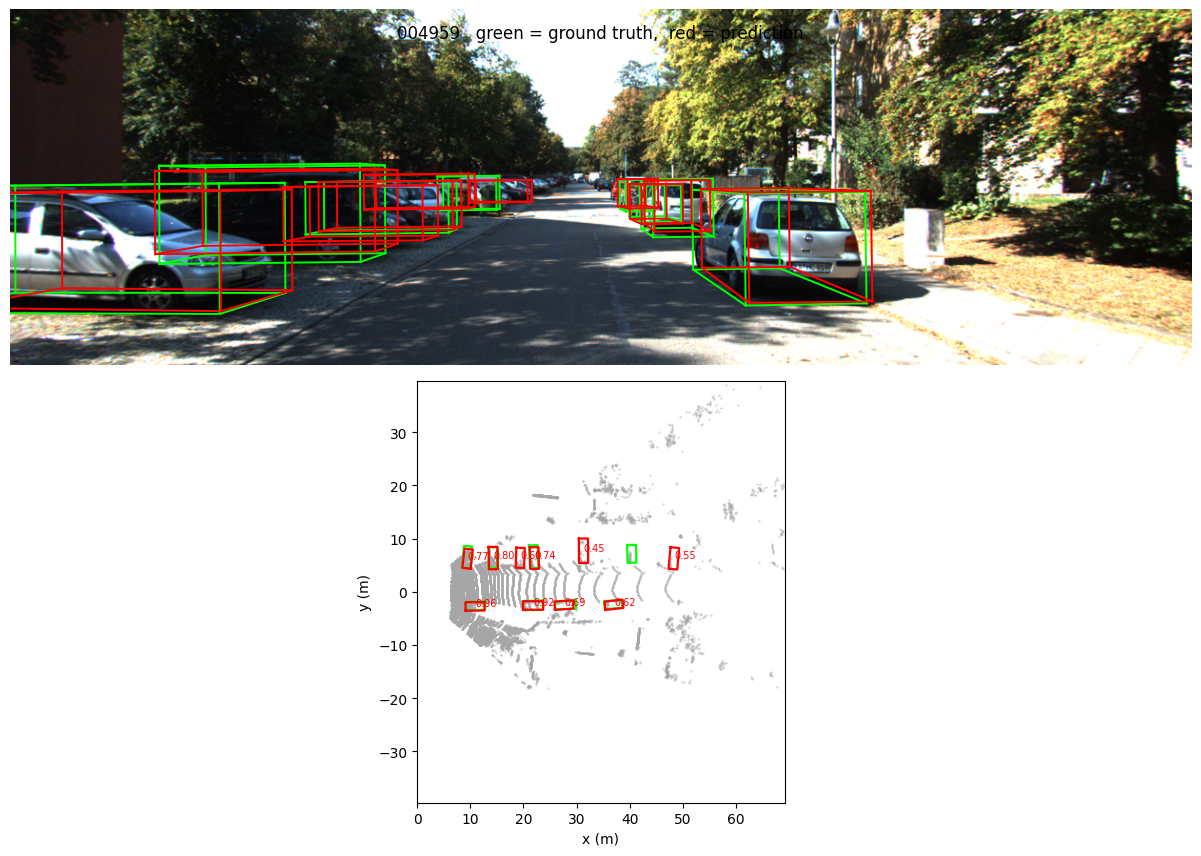

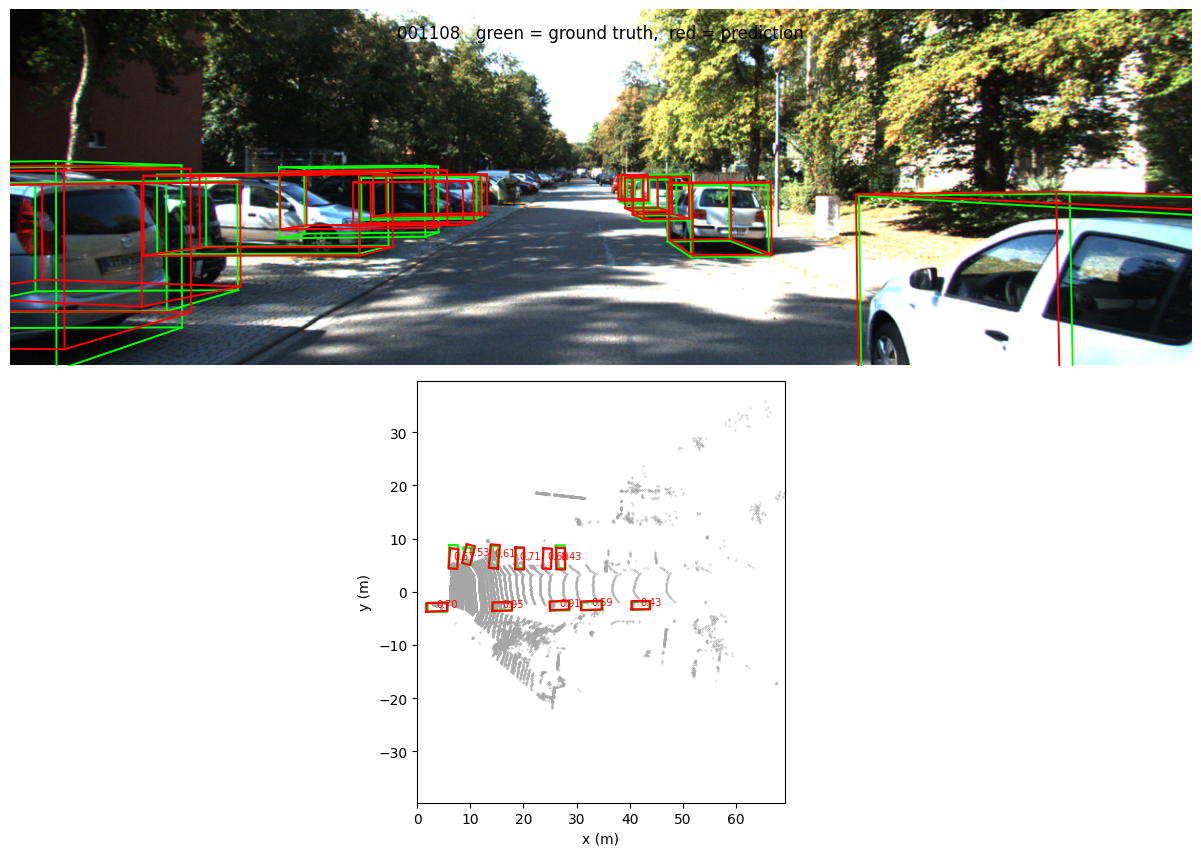

In [20]:
# Cell 8 - A few frames at once, and the worst ones
for i in [1, 5, 12, 27]:
    show(i)

# frames with the largest count mismatch between prediction and ground truth
err = sorted(range(len(DETS)), key=lambda i: -abs(len(DETS[i]) - len(GTS[i])))[:3]
print("largest count mismatches:", [(FIDS[i], len(DETS[i]), len(GTS[i])) for i in err])
for i in err:
    show(i)